# KNN Case Study: Diabetes Prediction (`KNN_Diabetes.ipynb`)

**Objective:** Build, tune, and evaluate a **K-Nearest Neighbors (KNN)** classification model to predict whether a patient has diabetes (`Outcome`: `1` = Diabetes, `0` = No Diabetes) using `diabetes_dataset.csv`.

### Workflow
1. **Import and Explore the Dataset** (shape, data types, missing values, zero-value audit, summary statistics, and visualizations)
2. **Data Preprocessing** (convert biologically invalid zeros to `NaN`, explain imputation and feature scaling for distance-based KNN)
3. **Train-Test Split & Leakage-Free Preprocessing** (stratified 80/20 split, median imputation, and `StandardScaler` fit on training data only)
4. **Implement & Tune KNN** (unscaled vs. scaled baseline `K=5`, and Stratified 5-Fold Cross-Validation across odd `K = 1..31`)
5. **Evaluate the Model** (accuracy, confusion matrix, precision/recall/F1-score, ROC-AUC, and ROC curve)
6. **Analysis of Results** (interpretation of findings, clinical trade-offs, and next steps)

## 1. Import and Explore the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [2]:
# Load the dataset (keep diabetes_dataset.csv in the same directory / Colab working folder)
df = pd.read_csv("diabetes_dataset.csv")

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 768 rows, 9 columns


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Inspect data types, non-null counts, explicit missing values, and duplicate rows
print("--- Dataset Info ---")
df.info()

print("\n--- Explicit Missing Values (NaN) ---")
print(df.isnull().sum())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

--- Explicit Missing Values (NaN) ---
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPed

In [4]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
# Check target class distribution and hidden zero values in physiological features
print("--- Target Distribution (Outcome) ---")
outcome_counts = df["Outcome"].value_counts()
outcome_pct = df["Outcome"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Count": outcome_counts, "Percentage (%)": outcome_pct.round(2)}))

zero_check_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_summary = pd.DataFrame({
    "Zero Count": (df[zero_check_cols] == 0).sum(),
    "Zero (%)": ((df[zero_check_cols] == 0).mean() * 100).round(2),
})
print("\n--- Biologically Invalid Zero Counts ---")
print(zero_summary)

--- Target Distribution (Outcome) ---
         Count  Percentage (%)
Outcome                       
0          500            65.1
1          268            34.9

--- Biologically Invalid Zero Counts ---
               Zero Count  Zero (%)
Glucose                 5      0.65
BloodPressure          35      4.56
SkinThickness         227     29.56
Insulin               374     48.70
BMI                    11      1.43


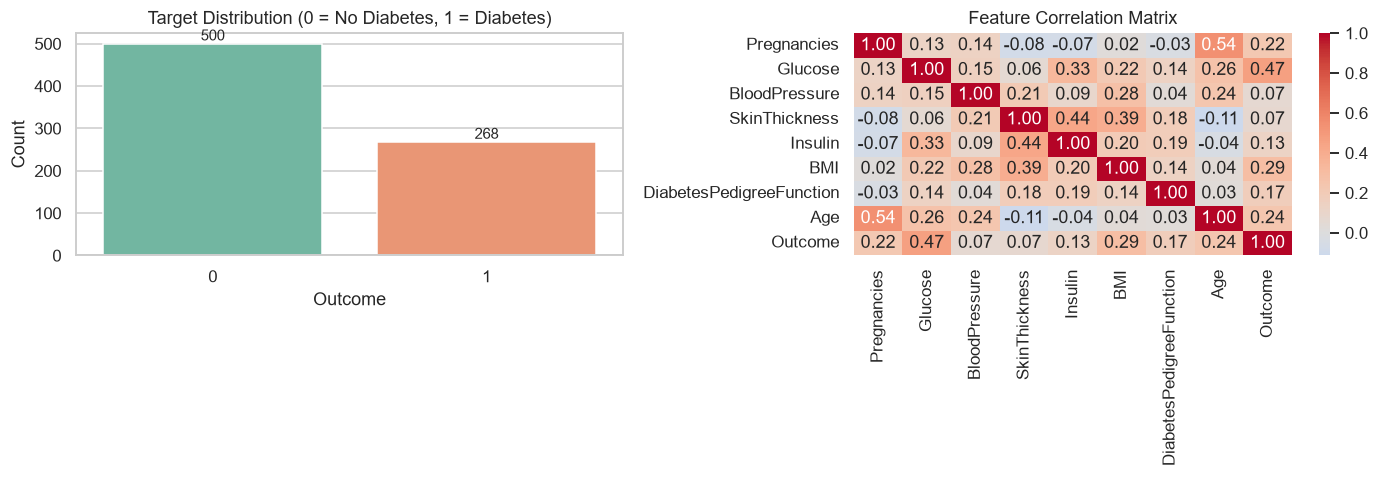

In [6]:
# Exploratory visualizations: target balance and feature correlation matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x="Outcome", hue="Outcome", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Target Distribution (0 = No Diabetes, 1 = Diabetes)")
axes[0].set_xlabel("Outcome")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )

corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False, ax=axes[1])
axes[1].set_title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

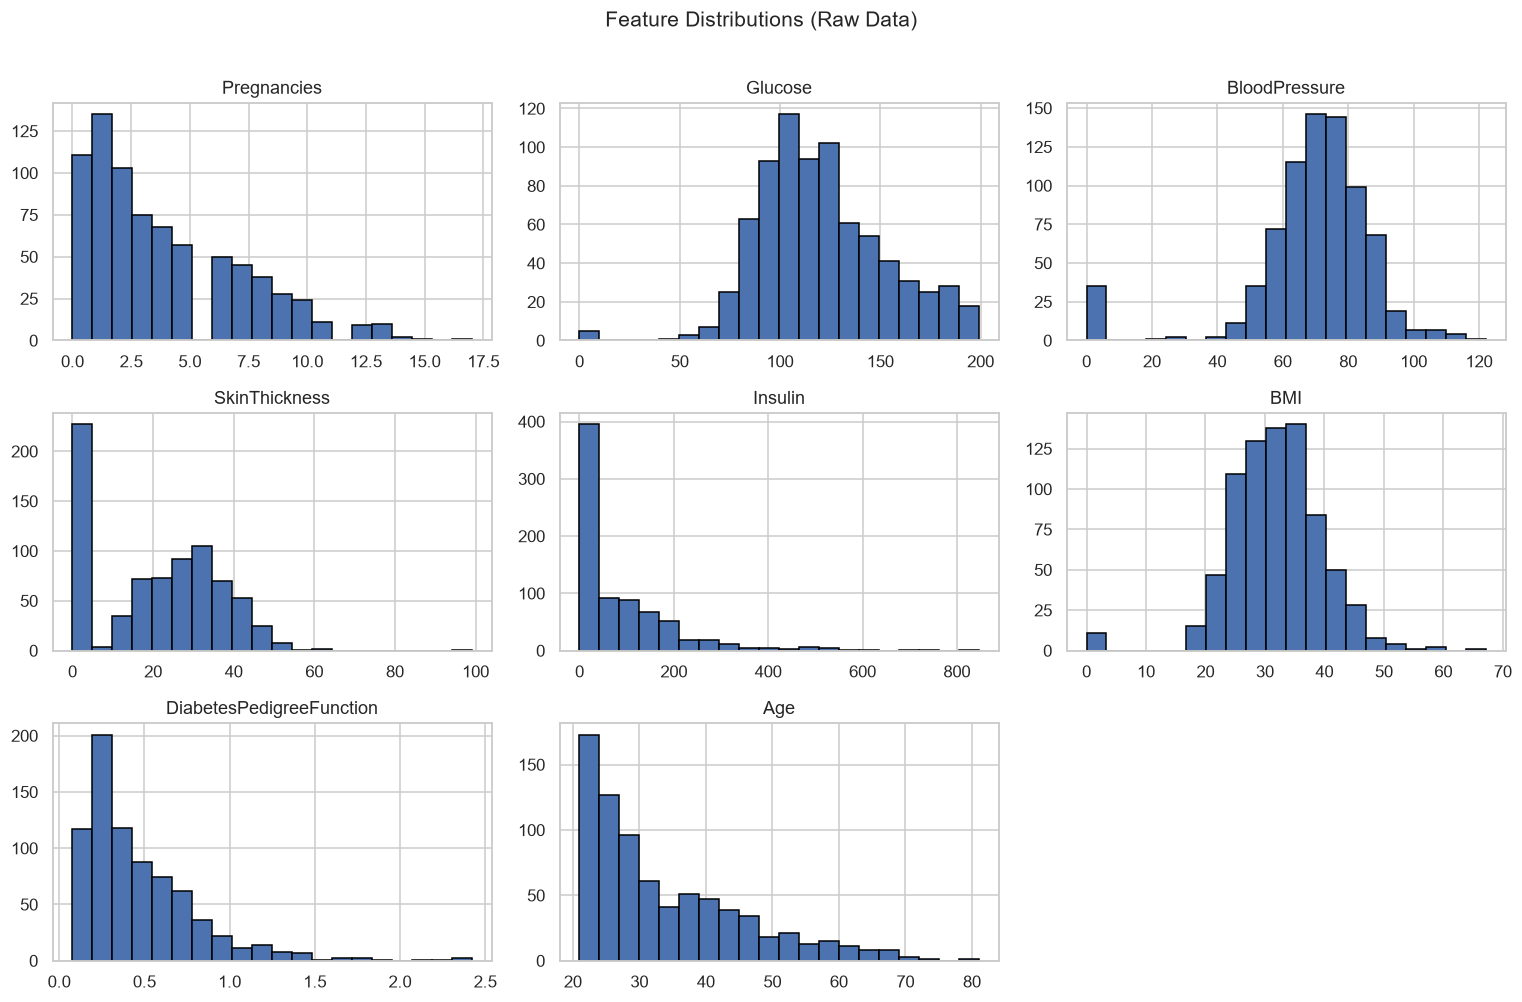

In [7]:
# Histograms of all numeric features
df.drop(columns=["Outcome"]).hist(bins=20, figsize=(14, 9), edgecolor="black", color="#4C72B0")
plt.suptitle("Feature Distributions (Raw Data)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 2. Data Preprocessing

Although `df.isnull().sum()` shows `0` explicit `NaN` values, physiological measurements such as **Glucose**, **BloodPressure**, **SkinThickness**, **Insulin**, and **BMI** cannot physically equal `0` in a living patient. In this dataset, `0` encodes missing measurements.

- **Missing Value Handling:** Replace `0` with `np.nan` in those 5 columns, then impute missing entries using the **median** (robust to skewed distributions like `Insulin` and `SkinThickness`).
- **Feature Scaling:** KNN relies on Euclidean distance between data points. Without scaling, features with large ranges (e.g., `Insulin` up to 846, `Glucose` up to 199) dominate small-range features (e.g., `DiabetesPedigreeFunction` ~0.08–2.42). Therefore, **Standardization (`StandardScaler`)** is essential.

> **Best Practice (Preventing Data Leakage):** Both the median imputer and the `StandardScaler` are **fit strictly on the training set** after the train-test split, and then used to transform the test set.

In [8]:
# Replace biologically invalid zeros with NaN in clinical measurement columns
df_clean = df.copy()
cols_with_invalid_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_clean[cols_with_invalid_zeros] = df_clean[cols_with_invalid_zeros].replace(0, np.nan)

print("--- Missing Values After Marking Invalid Zeros as NaN ---")
missing_df = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing (%)": (df_clean.isnull().mean() * 100).round(2),
})
print(missing_df)

--- Missing Values After Marking Invalid Zeros as NaN ---
                          Missing Count  Missing (%)
Pregnancies                           0         0.00
Glucose                               5         0.65
BloodPressure                        35         4.56
SkinThickness                       227        29.56
Insulin                             374        48.70
BMI                                  11         1.43
DiabetesPedigreeFunction              0         0.00
Age                                   0         0.00
Outcome                               0         0.00


## 3. Split the Dataset into Training and Testing Sets

We separate predictors (`X`) and target (`y`), perform a **stratified 80/20 train-test split** (`random_state=42`) so both splits preserve the ~65% / 35% class ratio, and then fit our preprocessing steps (`SimpleImputer(strategy="median")` + `StandardScaler()`) on `X_train` only.

In [9]:
X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"Train Outcome positive rate: {y_train.mean():.4f}")
print(f"Test  Outcome positive rate: {y_test.mean():.4f}")

X_train shape: (614, 8), X_test shape: (154, 8)
Train Outcome positive rate: 0.3485
Test  Outcome positive rate: 0.3506


In [10]:
# Fit imputer and scaler on training data only, then transform both train and test sets
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Remaining NaNs in X_train_scaled:", np.isnan(X_train_scaled).sum())
print("Remaining NaNs in X_test_scaled :", np.isnan(X_test_scaled).sum())

scaled_stats = pd.DataFrame({
    "Train Mean": X_train_scaled.mean(axis=0).round(4),
    "Train Std": X_train_scaled.std(axis=0).round(4),
}, index=X.columns)
scaled_stats

Remaining NaNs in X_train_scaled: 0
Remaining NaNs in X_test_scaled : 0


,Train Mean,Train Std
Pregnancies,-0.0,1.0
Glucose,-0.0,1.0
BloodPressure,0.0,1.0
SkinThickness,-0.0,1.0
Insulin,-0.0,1.0
BMI,0.0,1.0
DiabetesPedigreeFunction,-0.0,1.0
Age,-0.0,1.0


## 4. Implement the K-Nearest Neighbors (KNN) Algorithm

We will:
1. Check the impact of feature scaling by comparing an **unscaled KNN (`K=5`)** vs. a **scaled KNN (`K=5`)**.
2. Use **5-Fold Stratified Cross-Validation** on the training set (inside a leakage-free `Pipeline`) to evaluate odd values of $K$ from `1` to `31` and choose the optimal `K`.
3. Train the final KNN model with the selected `K`.

In [11]:
# 1. Baseline K=5: Unscaled vs. Scaled comparison
knn_unscaled = KNeighborsClassifier(n_neighbors=5)
knn_unscaled.fit(X_train_imputed, y_train)
y_pred_unscaled = knn_unscaled.predict(X_test_imputed)
y_prob_unscaled = knn_unscaled.predict_proba(X_test_imputed)[:, 1]
acc_unscaled = accuracy_score(y_test, y_pred_unscaled)

knn_baseline = KNeighborsClassifier(n_neighbors=5)
knn_baseline.fit(X_train_scaled, y_train)
y_pred_baseline = knn_baseline.predict(X_test_scaled)
y_prob_baseline = knn_baseline.predict_proba(X_test_scaled)[:, 1]
acc_baseline = accuracy_score(y_test, y_pred_baseline)

print(f"Unscaled KNN (K=5) Test Accuracy: {acc_unscaled:.4f}")
print(f"Scaled   KNN (K=5) Test Accuracy: {acc_baseline:.4f}")

Unscaled KNN (K=5) Test Accuracy: 0.6753
Scaled   KNN (K=5) Test Accuracy: 0.7532


In [12]:
# 2. Tune K using 5-fold Stratified Cross-Validation on the training set
k_values = list(range(1, 32, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = []
train_scores = []

for k in k_values:
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_scores.append(scores.mean())

    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_train_scaled, y_train)
    train_scores.append(accuracy_score(y_train, knn_k.predict(X_train_scaled)))

best_idx = int(np.argmax(cv_scores))
best_k = k_values[best_idx]
best_cv_acc = cv_scores[best_idx]

print(f"Optimal K (via 5-Fold CV): {best_k}")
print(f"Best 5-Fold CV Accuracy  : {best_cv_acc:.4f}")

Optimal K (via 5-Fold CV): 13
Best 5-Fold CV Accuracy  : 0.7752


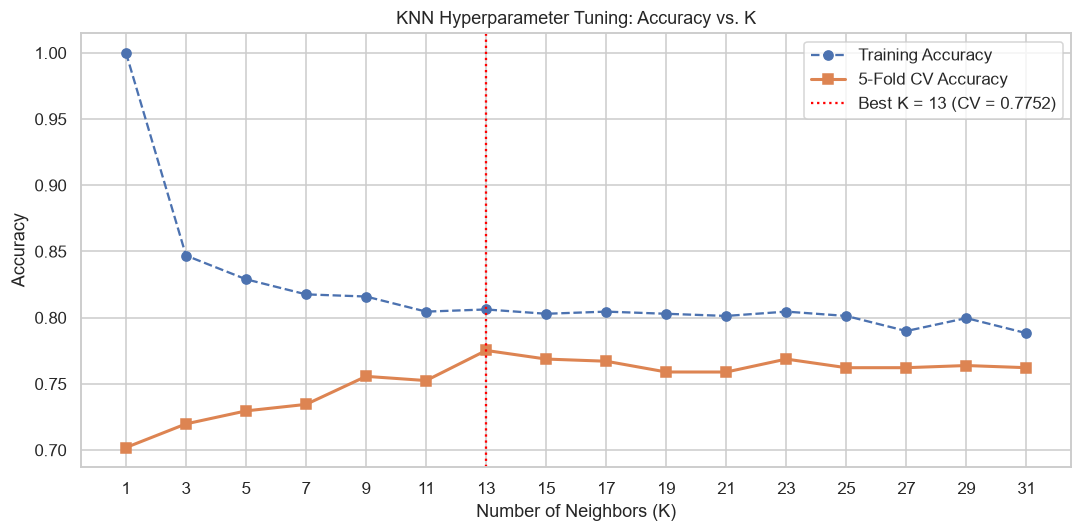

In [13]:
# Plot Training vs. 5-Fold CV Accuracy across K values
plt.figure(figsize=(10, 5))
plt.plot(k_values, train_scores, marker="o", linestyle="--", label="Training Accuracy")
plt.plot(k_values, cv_scores, marker="s", linewidth=2, label="5-Fold CV Accuracy")
plt.axvline(best_k, color="red", linestyle=":", linewidth=1.5, label=f"Best K = {best_k} (CV = {best_cv_acc:.4f})")
plt.xticks(k_values)
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Hyperparameter Tuning: Accuracy vs. K")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# 3. Train final KNN model with optimal K and generate predictions
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)

y_pred = knn_final.predict(X_test_scaled)
y_prob = knn_final.predict_proba(X_test_scaled)[:, 1]

## 5. Evaluate the Model

We evaluate the tuned KNN model (`K = 13`) on the held-out test set using **Accuracy**, **Confusion Matrix**, **Precision / Recall / F1-Score**, and **ROC-AUC**, and compare it against the `K = 5` unscaled and scaled baselines.

In [15]:
test_acc = accuracy_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)

print(f"Final KNN (K={best_k}) Test Accuracy : {test_acc:.4f}")
print(f"Final KNN (K={best_k}) Test ROC-AUC  : {test_auc:.4f}")
print("\n--- Confusion Matrix ---")
print(cm)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=["No Diabetes (0)", "Diabetes (1)"]))

comparison = pd.DataFrame({
    "Model": ["Unscaled KNN (K=5)", "Scaled KNN (K=5)", f"Scaled KNN (K={best_k}, CV-Best)"],
    "Test Accuracy": [
        round(acc_unscaled, 4),
        round(acc_baseline, 4),
        round(test_acc, 4),
    ],
    "Test ROC-AUC": [
        round(roc_auc_score(y_test, y_prob_unscaled), 4),
        round(roc_auc_score(y_test, y_prob_baseline), 4),
        round(test_auc, 4),
    ],
})
comparison

Final KNN (K=13) Test Accuracy : 0.7143
Final KNN (K=13) Test ROC-AUC  : 0.7944

--- Confusion Matrix ---
[[82 18]
 [26 28]]

--- Classification Report ---
                 precision    recall  f1-score   support

No Diabetes (0)       0.76      0.82      0.79       100
   Diabetes (1)       0.61      0.52      0.56        54

       accuracy                           0.71       154
      macro avg       0.68      0.67      0.67       154
   weighted avg       0.71      0.71      0.71       154



,Model,Test Accuracy,Test ROC-AUC
0,Unscaled KNN (K=5),0.6753,0.7005
1,Scaled KNN (K=5),0.7532,0.7899
2,"Scaled KNN (K=13, CV-Best)",0.7143,0.7944


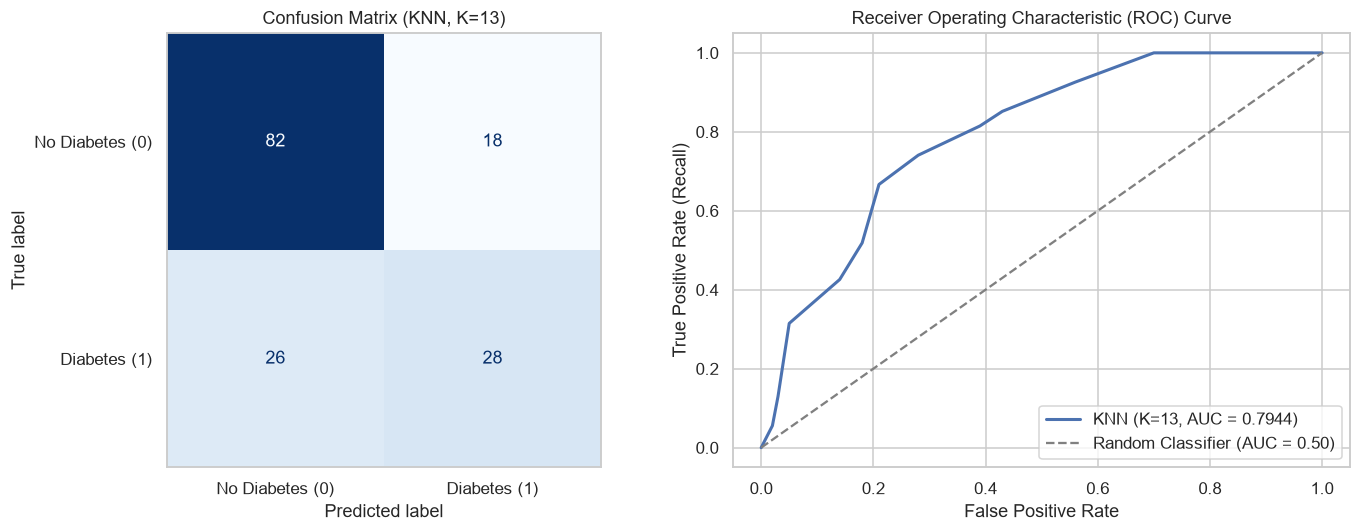

In [16]:
# Side-by-side Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes (0)", "Diabetes (1)"])
disp.plot(cmap="Blues", ax=axes[0], colorbar=False)
axes[0].grid(False)
axes[0].set_title(f"Confusion Matrix (KNN, K={best_k})")

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, linewidth=2, label=f"KNN (K={best_k}, AUC = {test_auc:.4f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].set_title("Receiver Operating Characteristic (ROC) Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 6. Analysis of Results

1. **Data Quality & Hidden Missing Values:**
   - The dataset contains **768 rows and 9 columns** (7 `int64`, 2 `float64`) with **0 duplicate rows** and **0 explicit `NaN` values**, and a moderate class imbalance (**500** non-diabetic `65.1%` vs. **268** diabetic `34.9%`).
   - However, several physiological columns contained **biologically invalid zeros**: `Insulin` (**48.70%**, 374 zeros), `SkinThickness` (**29.56%**, 227 zeros), `BloodPressure` (**4.56%**, 35 zeros), `BMI` (**1.43%**, 11 zeros), and `Glucose` (**0.65%**, 5 zeros). Treating those zeros as `NaN` and imputing with training-set medians prevents distorted distance calculations.

2. **Impact of Feature Scaling:**
   - Because KNN relies on Euclidean distance, unscaled features caused `Insulin` and `Glucose` to dominate smaller-scale features like `DiabetesPedigreeFunction`.
   - Standardizing features with `StandardScaler` improved baseline (`K=5`) test accuracy from **0.6753** (unscaled) to **0.7532** (scaled) — a **+7.79 percentage point** gain.

3. **Hyperparameter Tuning (`K`) & Bias-Variance Trade-off:**
   - Small `K` values (e.g., `K=1`) overfit the training data (`100%` training accuracy with lower validation stability).
   - 5-Fold Stratified Cross-Validation on the `614`-row training set selected **`K = 13`** with a CV accuracy of **0.7752**.
   - On the held-out `154`-row test set, `K = 13` achieved **0.7143** accuracy and **0.7944 ROC-AUC** (compared to `K = 5` scaled at **0.7532** test accuracy — a normal fluctuation on a 154-sample test split, while `K = 13` yields strong probability ranking with ~0.794 ROC-AUC).

4. **Confusion Matrix & Clinical Interpretation (`K = 13`):**
   - **True Negatives (TN) = 82**, **False Positives (FP) = 18**, **False Negatives (FN) = 26**, **True Positives (TP) = 28**.
   - The model identifies non-diabetic patients well (**0.82 recall**, **0.79 F1** for class `0`), while diabetic recall is **0.52** (**0.61 precision**, **0.56 F1** for class `1`).
   - In medical screening, **False Negatives (26 missed diabetic cases)** carry higher clinical risk than False Positives.

5. **Potential Improvements:**
   - Tune the classification probability threshold (e.g., below `0.50` using the ROC curve) to increase diabetes **recall** at the expense of a slight drop in precision.
   - Explore distance-weighted KNN (`weights="distance"`), Manhattan distance (`p=1`), or alternative models such as Logistic Regression, Random Forest, or Gradient Boosting, especially given the ~48.7% missingness in `Insulin`.